**Diabetes Classification**

**Part I: EDA: Exploring the variables and association**

In [2254]:
#Importing libraries

import os
import math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, classification_report, roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2255]:
#Creating DataFrame for dataset:

df = pd.read_csv('/Users/hovantrung/Documents/NUS/DSA1101 Introduction to Data Science/code/DSA1101/Assignment 2/diabetes-dataset-2k.csv')
print(df.head())
print(df.shape) #The number of variables (including the response variable) is 9 and the number of patients is 2000.

#Checking the response column:

diabetes = df["diabetes"]
print(diabetes.value_counts())

   gender    age  hypertension  heart_disease smoking_history    bmi  \
0  Female   0.32             0              0         No Info  20.56   
1    Male  21.00             0              0           never  23.78   
2  Female  15.00             0              0           never  16.27   
3    Male  34.00             0              0           never  37.43   
4  Female  44.00             0              0          former  23.49   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  126         0  
1          6.0                  126         0  
2          6.0                  160         0  
3          6.1                   85         0  
4          4.5                   80         0  
(2000, 9)
diabetes
0    1830
1     170
Name: count, dtype: int64


In [2256]:
#Re-grouping the smoking_history column into 3 groups: Yes, No, and No Info.

df.loc[df["smoking_history"] == "current", "smoking_history"] = "Yes"
df.loc[df["smoking_history"] == "ever", "smoking_history"] = "Yes"
df.loc[df["smoking_history"] == "former", "smoking_history"] = "Yes"

df.loc[df["smoking_history"] == "never", "smoking_history"] = "No"
df.loc[df["smoking_history"] == "not current", "smoking_history"] = "No"

Males with diabetes: 10.943. Females with diabetes: 6.661.
The difference: 4.282.


<Axes: xlabel='gender', ylabel='diabetes'>

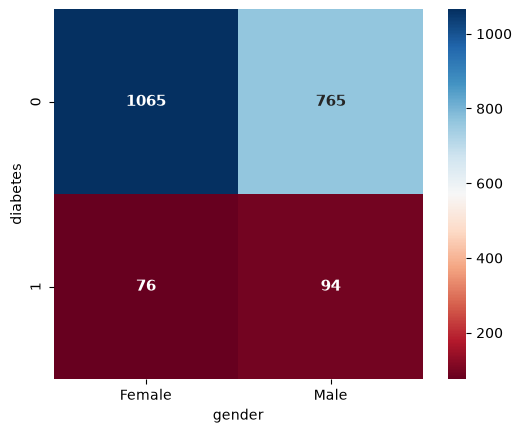

In [2257]:
#Checking the association between the response and each input variable:

#gender:

tab_gender = pd.crosstab(diabetes, df["gender"]) 

#proportion:

males = round((tab_gender.loc[1, "Male"] / tab_gender["Male"].sum()) * 100,3)
females = round((tab_gender.loc[1, "Female"] / tab_gender["Female"].sum()) * 100,3)
diff = males - females

print(f"Males with diabetes: {males}. Females with diabetes: {females}.")
print(f"The difference: {diff}.")

#table:

sns.heatmap(tab_gender, cmap='RdBu', vmin=tab_gender.min().min(), vmax=tab_gender.max().max(), 
            annot=True, annot_kws={'fontsize':11, 'fontweight':'bold'}, fmt='d',
           square=True)

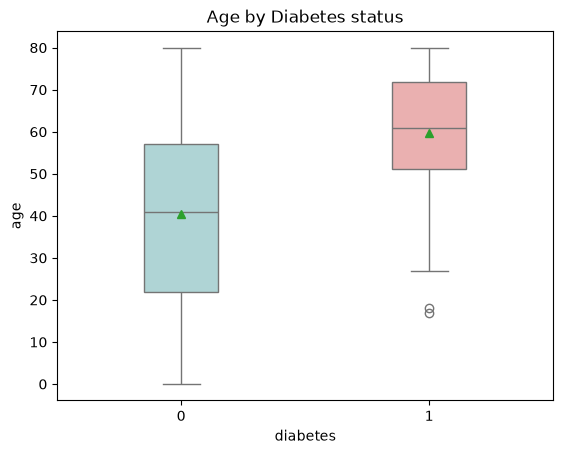

In [2258]:
#age:

sns.boxplot(x=df["diabetes"], y=df["age"], width=0.3, palette=["#A8DADC", "#F4A6A6"],
           hue=df["diabetes"], dodge=False, legend=False,
           showmeans=True)
plt.title("Age by Diabetes status")
plt.show()

Hypertension with diabetes: 23.333. No hypertension with diabetes: 7.297.
The difference: 16.036.


<Axes: xlabel='hypertension', ylabel='diabetes'>

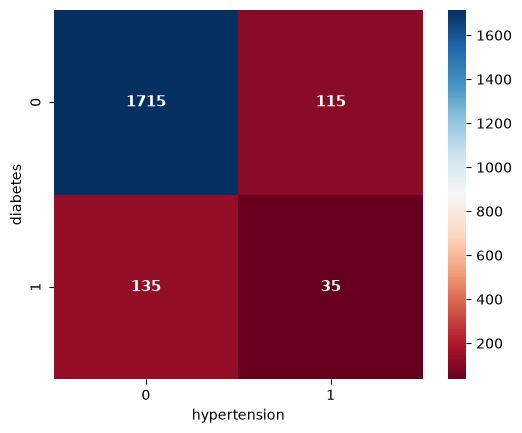

In [2259]:
#hypertension:

tab_hypertension = pd.crosstab(diabetes, df["hypertension"]) 

#proportion:

h = round((tab_hypertension.loc[1, 1] / tab_hypertension[1].sum()) * 100,3)
no_h = round((tab_hypertension.loc[1, 0] / tab_hypertension[0].sum()) * 100,3)
diff = round(h - no_h,3)

print(f"Hypertension with diabetes: {h}. No hypertension with diabetes: {no_h}.")
print(f"The difference: {diff}.")

#table:

sns.heatmap(tab_hypertension, cmap='RdBu', vmin=tab_hypertension.min().min(), vmax=tab_hypertension.max().max(), annot=True, 
            annot_kws={'fontsize':11, 'fontweight':'bold'}, fmt='d',
           square=True)

Heart disease with diabetes: 36.145. No heart disease with diabetes: 7.303.
The difference: 28.842.


<Axes: xlabel='heart_disease', ylabel='diabetes'>

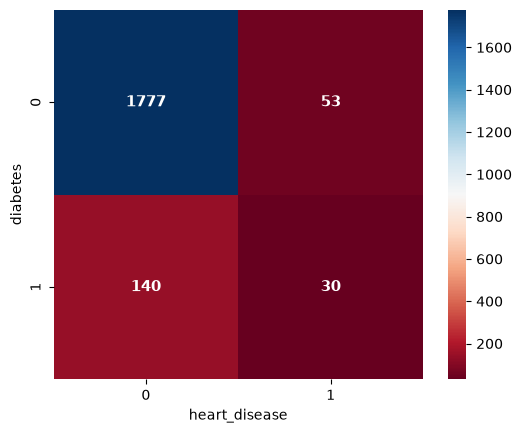

In [2260]:
#heart_disease:

tab_heart_disease = pd.crosstab(diabetes, df["heart_disease"])

#prop:

hd = round((tab_heart_disease.loc[1, 1] / tab_heart_disease[1].sum()) * 100,3)
no_hd = round((tab_heart_disease.loc[1, 0] / tab_heart_disease[0].sum()) * 100,3)
diff = round(hd - no_hd,3)

print(f"Heart disease with diabetes: {hd}. No heart disease with diabetes: {no_hd}.")
print(f"The difference: {diff}.")

#table:

sns.heatmap(tab_heart_disease, cmap='RdBu', vmin=tab_heart_disease.min().min(), vmax=tab_heart_disease.max().max(), annot=True, 
            annot_kws={'fontsize':11, 'fontweight':'bold'}, fmt='d',
           square=True)

smoking_history
No         840
No Info    721
Yes        439
Name: count, dtype: int64
Smoking Yes with diabetes: 14.806. Smoking No with diabetes: 9.286.
The difference: 5.52.


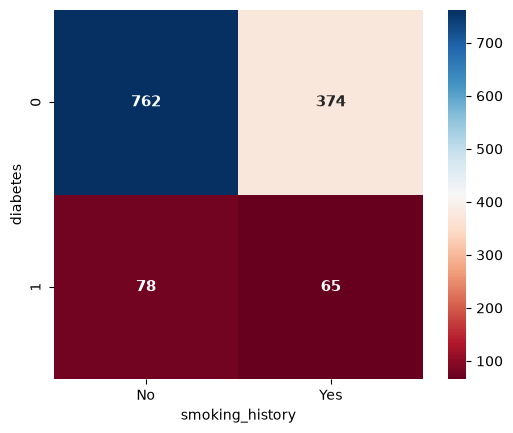

In [2261]:
#smoking_history: Let the "No" group be the reference group

print(df["smoking_history"].value_counts()) 

#We also notice that the No Info group comprises of a 
#large part of the dataset, thus we cannot omit it.

yes_no = df.loc[df["smoking_history"] != "No Info", "smoking_history"]
noinfo_no = df.loc[df["smoking_history"] != "Yes", "smoking_history"]

#Contingency table of "Yes" and "No":

tab_smoking_yes_no = pd.crosstab(diabetes, yes_no)

sns.heatmap(tab_smoking_yes_no, cmap='RdBu', vmin=tab_smoking_yes_no.min().min(), vmax=tab_smoking_yes_no.max().max(), annot=True, 
            annot_kws={'fontsize':11, 'fontweight':'bold'}, fmt='d',
           square=True)

#proportion of "Yes" and "No

yes = round((tab_smoking_yes_no.loc[1, "Yes"] / tab_smoking_yes_no["Yes"].sum()) * 100,3)
no = round((tab_smoking_yes_no.loc[1, "No"] / tab_smoking_yes_no["No"].sum()) * 100,3)
diff = round(yes - no,3)

print(f"Smoking Yes with diabetes: {yes}. Smoking No with diabetes: {no}.")
print(f"The difference: {diff}.")

Smoking No Info with diabetes: 3.745. Smoking No with diabetes: 9.286.
The difference: 5.541.


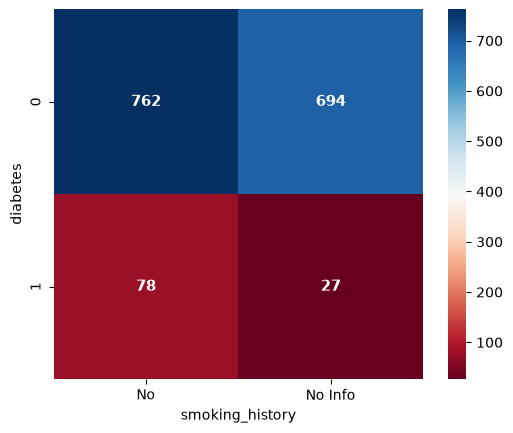

In [2262]:
#Contingency table of "No Info" and "No":

tab_smoking_no_no_info = pd.crosstab(diabetes, noinfo_no)

sns.heatmap(tab_smoking_no_no_info, cmap='RdBu', vmin=tab_smoking_no_no_info.min().min(), vmax=tab_smoking_no_no_info.max().max(), annot=True, 
            annot_kws={'fontsize':11, 'fontweight':'bold'}, fmt='d',
           square=True)

#proportion of "No" and "No info":

no_info = round((tab_smoking_no_no_info.loc[1, "No Info"] / tab_smoking_no_no_info["No Info"].sum()) * 100, 3)
diff = round(no - no_info,3)

print(f"Smoking No Info with diabetes: {no_info}. Smoking No with diabetes: {no}.")
print(f"The difference: {diff}.")

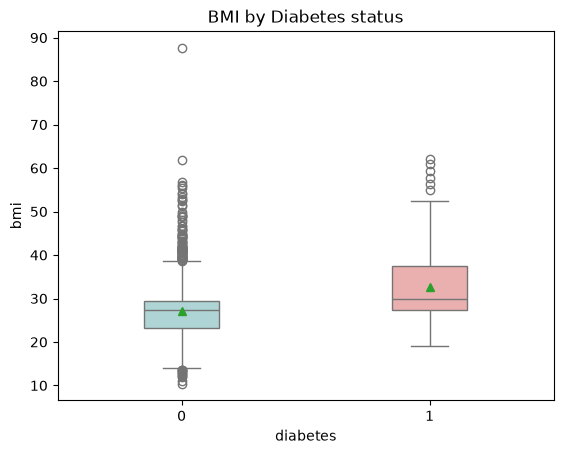

In [2263]:
#bmi:

sns.boxplot(x=df["diabetes"], y=df["bmi"], width=0.3, palette=["#A8DADC", "#F4A6A6"],
           hue=df["diabetes"], dodge=False, legend=False,
            showmeans=True)
plt.title("BMI by Diabetes status")
plt.show()

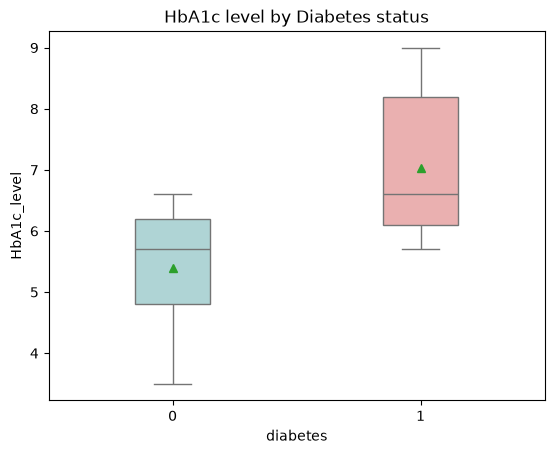

In [2264]:
#HbA1c_level:

sns.boxplot(x=df["diabetes"], y=df["HbA1c_level"], width=0.3, palette=["#A8DADC", "#F4A6A6"],
           hue=df["diabetes"], dodge=False, legend=False,
           showmeans=True)
plt.title("HbA1c level by Diabetes status")
plt.show()

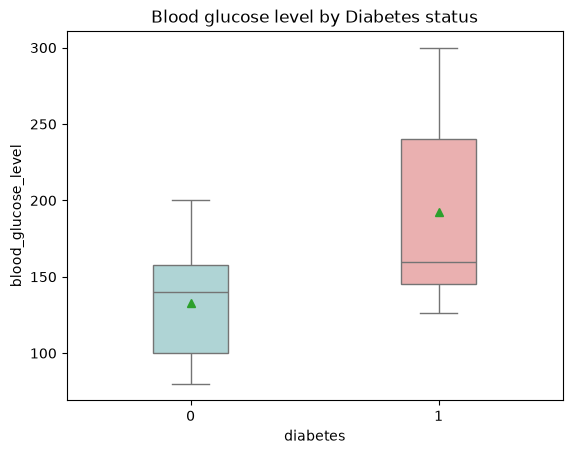

In [2265]:
#blood_glucose_level:

sns.boxplot(x=df["diabetes"], y=df["blood_glucose_level"], width=0.3, palette=["#A8DADC", "#F4A6A6"],
           hue=df["diabetes"], dodge=False, legend=False,
            showmeans=True)
plt.title("Blood glucose level by Diabetes status")
plt.show()

In [2266]:
#Encoding gender:

df["gender"] = np.where(df["gender"] == "Female", 1, 0)

In [2267]:
#Enconding smoking_history by labeling No, No Info as 0 and Yes as 1:

df["smoking_history"] = np.where(df["smoking_history"] == "Yes", 1, 0)

In [2268]:
#Defining the chosen features:

features = ["gender", "age", "hypertension", "heart_disease", "smoking_history", "bmi", "HbA1c_level", "blood_glucose_level"]

In [2269]:
print(df.head())

   gender    age  hypertension  heart_disease  smoking_history    bmi  \
0       1   0.32             0              0                0  20.56   
1       0  21.00             0              0                0  23.78   
2       1  15.00             0              0                0  16.27   
3       0  34.00             0              0                0  37.43   
4       1  44.00             0              0                1  23.49   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  126         0  
1          6.0                  126         0  
2          6.0                  160         0  
3          6.1                   85         0  
4          4.5                   80         0  


**Part II: Methods**

In [2270]:
#Forming train set and test set:

train_set, test_set = train_test_split(
    df,
    test_size=0.20, 
    random_state=1101,
    shuffle = True,
    stratify=df['diabetes'])

train_X = train_set[features]
train_y = train_set["diabetes"]
test_X = test_set[features]
test_y = test_set["diabetes"]

In [2271]:
#Standardizing data:

scaler = StandardScaler()
train_X_scaled = scaler.fit_transform(train_X)
test_X_scaled = scaler.transform(test_X)

In [2272]:
#Def TPR and FPR finder:

def tpr_fpr_find(test, pred):

    confusion_matrix_table = pd.crosstab(
        pd.Series(test.to_numpy(), name="Actual"),
        pd.Series(np.asarray(pred), name="Predicted")
    )
    
    tp = confusion_matrix_table.loc[1,1]
    fn = confusion_matrix_table.loc[1, 0]
    fp = confusion_matrix_table.loc[0, 1]
    tn = confusion_matrix_table.loc[0, 0]
    
    tpr = round((tp / (tp + fn)),3)
    fpr = round(fp / (fp + tn), 3)
    
    return tpr, fpr

**1. KNN:**

In [2273]:
K = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]

results = []

for k in K:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(train_X_scaled, train_y)
    pred_knn = knn.predict(test_X_scaled)

    tpr_knn, fpr_knn = tpr_fpr_find(test_y, pred_knn)
    precision_knn = precision_score(test_y, pred_knn)

    result = [k, tpr_knn, fpr_knn, precision_knn]

    results.append(result)

#DataFrame of all K:

df_knn = pd.DataFrame(
    results,
    columns=["K", "tpr", "fpr", "precision"]
)

print(df_knn)

#Filtering K by TPR (first try) and precision (second try):

K_tuning = df_knn.loc[
        df_knn["tpr"] == df_knn["tpr"].max()
    ]
K_tuning = K_tuning.loc[
        K_tuning["fpr"] == K_tuning["fpr"].min()
    ]
K_tuning = K_tuning.loc[
        K_tuning["precision"] == K_tuning["precision"].max()
    ]

print(K_tuning)

"""

After filtering by TPR, FPR, and precision, we have 5 with the highest TPR and 
precision, as well as the lowest FPR.

Thus, the best KNN model is the model where k = 5.

"""

    K    tpr    fpr  precision
0   3  0.412  0.014   0.736842
1   5  0.412  0.008   0.823529
2   7  0.382  0.005   0.866667
3   9  0.382  0.003   0.928571
4  11  0.324  0.000   1.000000
5  13  0.294  0.000   1.000000
6  15  0.265  0.000   1.000000
7  17  0.265  0.000   1.000000
8  19  0.265  0.000   1.000000
9  21  0.235  0.000   1.000000
   K    tpr    fpr  precision
1  5  0.412  0.008   0.823529


'\n\nAfter filtering by TPR, FPR, and precision, we have 5 with the highest TPR and \nprecision, as well as the lowest FPR.\n\nThus, the best KNN model is the model where k = 5.\n\n'

**2. Decision Tree:**

In [2274]:
#DT:
#Goodness-of-fit of the Decision Tree: 
#Finding the best max_depth and min_samples_split.

max_depth = [3, 5, 7, 9, 11]
min_samples_split = [10, 20, 30, 40, 50, 100]

results = []

for d in max_depth: 
    for m in min_samples_split:
        DT = DecisionTreeClassifier(criterion='entropy', 
                                    max_depth=d,
                                    min_samples_split=m,
                                    random_state=1101)
        DT.fit(train_X, train_y)
        pred_DT = DT.predict(test_X)
    
        tpr_DT, fpr_DT = tpr_fpr_find(test_y, pred_DT)
        precision_DT = precision_score(test_y, pred_DT)

        result = [d, m, tpr_DT, fpr_DT, precision_DT]
    
        results.append(result)

#DataFrame of all candidates, sorted in descending order:

df_DT = pd.DataFrame(
    results,
    columns=["max_depth", "min_samples_split", "tpr", "fpr", "precision"]
)

print(df_DT.sort_values(by="tpr", ascending=False).head(10))

"""

We will continue with max_depth 11 and min_samples_split 20.

"""

    max_depth  min_samples_split    tpr    fpr  precision
25         11                 20  0.706  0.014   0.827586
24         11                 10  0.706  0.011   0.857143
15          7                 40  0.676  0.003   0.958333
16          7                 50  0.676  0.003   0.958333
28         11                 50  0.676  0.003   0.958333
27         11                 40  0.676  0.011   0.851852
26         11                 30  0.676  0.011   0.851852
23          9                100  0.676  0.003   0.958333
22          9                 50  0.676  0.003   0.958333
21          9                 40  0.676  0.011   0.851852


'\n\nWe will continue with max_depth 11 and min_samples_split 20.\n\n'

**3. Logistic Regression:**

In [2275]:
#Forming M1:

M1 = smf.glm(
    formula="diabetes ~ C(gender) + age + C(hypertension) + C(heart_disease) + C(smoking_history) + bmi + HbA1c_level + blood_glucose_level",
    data=train_set,
    family=sm.families.Binomial(),
).fit()

M1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               diabetes   No. Observations:                 1600
Model:                            GLM   Df Residuals:                     1591
Model Family:                Binomial   Df Model:                            8
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -178.80
Date:                Wed, 28 Oct 2026   Deviance:                       357.59
Time:                        18:58:01   Pearson chi2:                 1.04e+03
No. Iterations:                     8   Pseudo R-squ. (CS):             0.3010
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 -26.3338      2.160    -12.193      0.000     -30.567     -22.101
C(gender)[T.1]             -0.6330      0.290     -2.180      0.029      -1.202      -0.064
C(hypertension)[T.1]        0.2985      0.429      0.696      0.487      -0.542       1.139
C(heart_disease)[T.1]       1.3800      0.422      3.268      0.001       0.552       2.208
C(smoking_history)[T.1]     0.4711      0.308      1.530      0.126      -0.132       1.075
age                         0.0314      0.008      3.919      0.000       0.016       0.047
bmi                         0.1004      0.017      5.780      0.000       0.066       0.134
HbA1c_level                 2.3201      0.271      8.559      0.000       1.789       2.851
blood_glucose_level         0.0322      0.004      8.755      0.000       0.025       0.039
===========================================================================================
"""

In [2276]:
#Removing hypertension and smoking_history from M1 to form M2:

M2 = smf.glm(
    formula="diabetes ~ C(gender) + age + C(heart_disease) + bmi + HbA1c_level + blood_glucose_level",
    data=train_set,
    family=sm.families.Binomial(),
).fit()

M2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               diabetes   No. Observations:                 1600
Model:                            GLM   Df Residuals:                     1593
Model Family:                Binomial   Df Model:                            6
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -180.21
Date:                Wed, 28 Oct 2026   Deviance:                       360.42
Time:                        18:58:02   Pearson chi2:                 1.02e+03
No. Iterations:                     8   Pseudo R-squ. (CS):             0.2998
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept               -26.0722      2.121    -12.294      0.000     -30.229     -21.916
C(gender)[T.1]           -0.6329      0.289     -2.191      0.028      -1.199      -0.067
C(heart_disease)[T.1]     1.4376      0.416      3.458      0.001       0.623       2.252
age                       0.0333      0.008      4.279      0.000       0.018       0.049
bmi                       0.0982      0.017      5.700      0.000       0.064       0.132
HbA1c_level               2.3065      0.268      8.614      0.000       1.782       2.831
blood_glucose_level       0.0319      0.004      8.785      0.000       0.025       0.039
=========================================================================================
"""

In [2277]:
#Removing hypertension from M1 to form M3:

M3 = smf.glm(
    formula="diabetes ~ C(gender) + age + C(heart_disease) + C(smoking_history) + bmi + HbA1c_level + blood_glucose_level",
    data=train_set,
    family=sm.families.Binomial(),
).fit()

M3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               diabetes   No. Observations:                 1600
Model:                            GLM   Df Residuals:                     1592
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -179.03
Date:                Wed, 28 Oct 2026   Deviance:                       358.06
Time:                        18:58:02   Pearson chi2:                 1.04e+03
No. Iterations:                     8   Pseudo R-squ. (CS):             0.3008
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 -26.2952      2.149    -12.235      0.000     -30.507     -22.083
C(gender)[T.1]             -0.6256      0.290     -2.158      0.031      -1.194      -0.058
C(heart_disease)[T.1]       1.4335      0.416      3.445      0.001       0.618       2.249
C(smoking_history)[T.1]     0.4775      0.308      1.550      0.121      -0.126       1.081
age                         0.0320      0.008      4.023      0.000       0.016       0.048
bmi                         0.1009      0.017      5.785      0.000       0.067       0.135
HbA1c_level                 2.3149      0.269      8.590      0.000       1.787       2.843
blood_glucose_level         0.0320      0.004      8.726      0.000       0.025       0.039
===========================================================================================
"""

In [2278]:
#Removing smoking_history from M1 to form M4:

M4 = smf.glm(
    formula="diabetes ~ C(gender) + age + C(hypertension) + C(heart_disease) + bmi + HbA1c_level + blood_glucose_level",
    data=train_set,
    family=sm.families.Binomial(),
).fit()

M4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               diabetes   No. Observations:                 1600
Model:                            GLM   Df Residuals:                     1592
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -179.95
Date:                Wed, 28 Oct 2026   Deviance:                       359.89
Time:                        18:58:02   Pearson chi2:                 1.03e+03
No. Iterations:                     8   Pseudo R-squ. (CS):             0.3000
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept               -26.1084      2.131    -12.252      0.000     -30.285     -21.932
C(gender)[T.1]           -0.6400      0.289     -2.212      0.027      -1.207      -0.073
C(hypertension)[T.1]      0.3183      0.431      0.739      0.460      -0.526       1.163
C(heart_disease)[T.1]     1.3866      0.420      3.299      0.001       0.563       2.211
age                       0.0326      0.008      4.154      0.000       0.017       0.048
bmi                       0.0977      0.017      5.696      0.000       0.064       0.131
HbA1c_level               2.3113      0.269      8.583      0.000       1.783       2.839
blood_glucose_level       0.0321      0.004      8.816      0.000       0.025       0.039
=========================================================================================
"""

In [2279]:
#Filtering by the highest TPR:

threshold = 0.5 #0.5 is chosen as the threshold to retain uniformity with KNN and DT models.

models = [M1, M2, M3, M4]
results = []

for i in models:
    pred_LR = (i.predict(test_X) >= threshold).astype(int) #Convert the probabilities to binary results using threshold 0.5.
    tpr_LR, fpr_LR = tpr_fpr_find(test_y, pred_LR)
    precision_LR = precision_score(test_y, pred_LR)
    
    result = [tpr_LR, fpr_LR, precision_LR]
        
    results.append(result)

#DataFrame of M1, M2, M3, M4:

df_LR = pd.DataFrame(
    results,
    columns=["tpr", "fpr", "precision"],
    index=["M1", "M2", "M3", "M4"])

print(df_LR.sort_values(by="tpr", ascending=False))

"""

All models have the same metrics.

M2 is less complex than others due to the removed variables of. Thus, we will choose M2.

"""

      tpr    fpr  precision
M1  0.559  0.005   0.904762
M2  0.559  0.005   0.904762
M3  0.559  0.005   0.904762
M4  0.559  0.005   0.904762


'\n\nAll models have the same metrics.\n\nM2 is less complex than others due to the removed variables of. Thus, we will choose M2.\n\n'

**4. Model comparision:**

In [2280]:
#Scaling the full data set (except for the response variable 'diabetes'):

full_data = df[train_X.columns]
full_data_scaled = scaler.transform(full_data)

#Full data set's response variable ('diabetes'):

full_diabetes = df["diabetes"]

+ Best models:

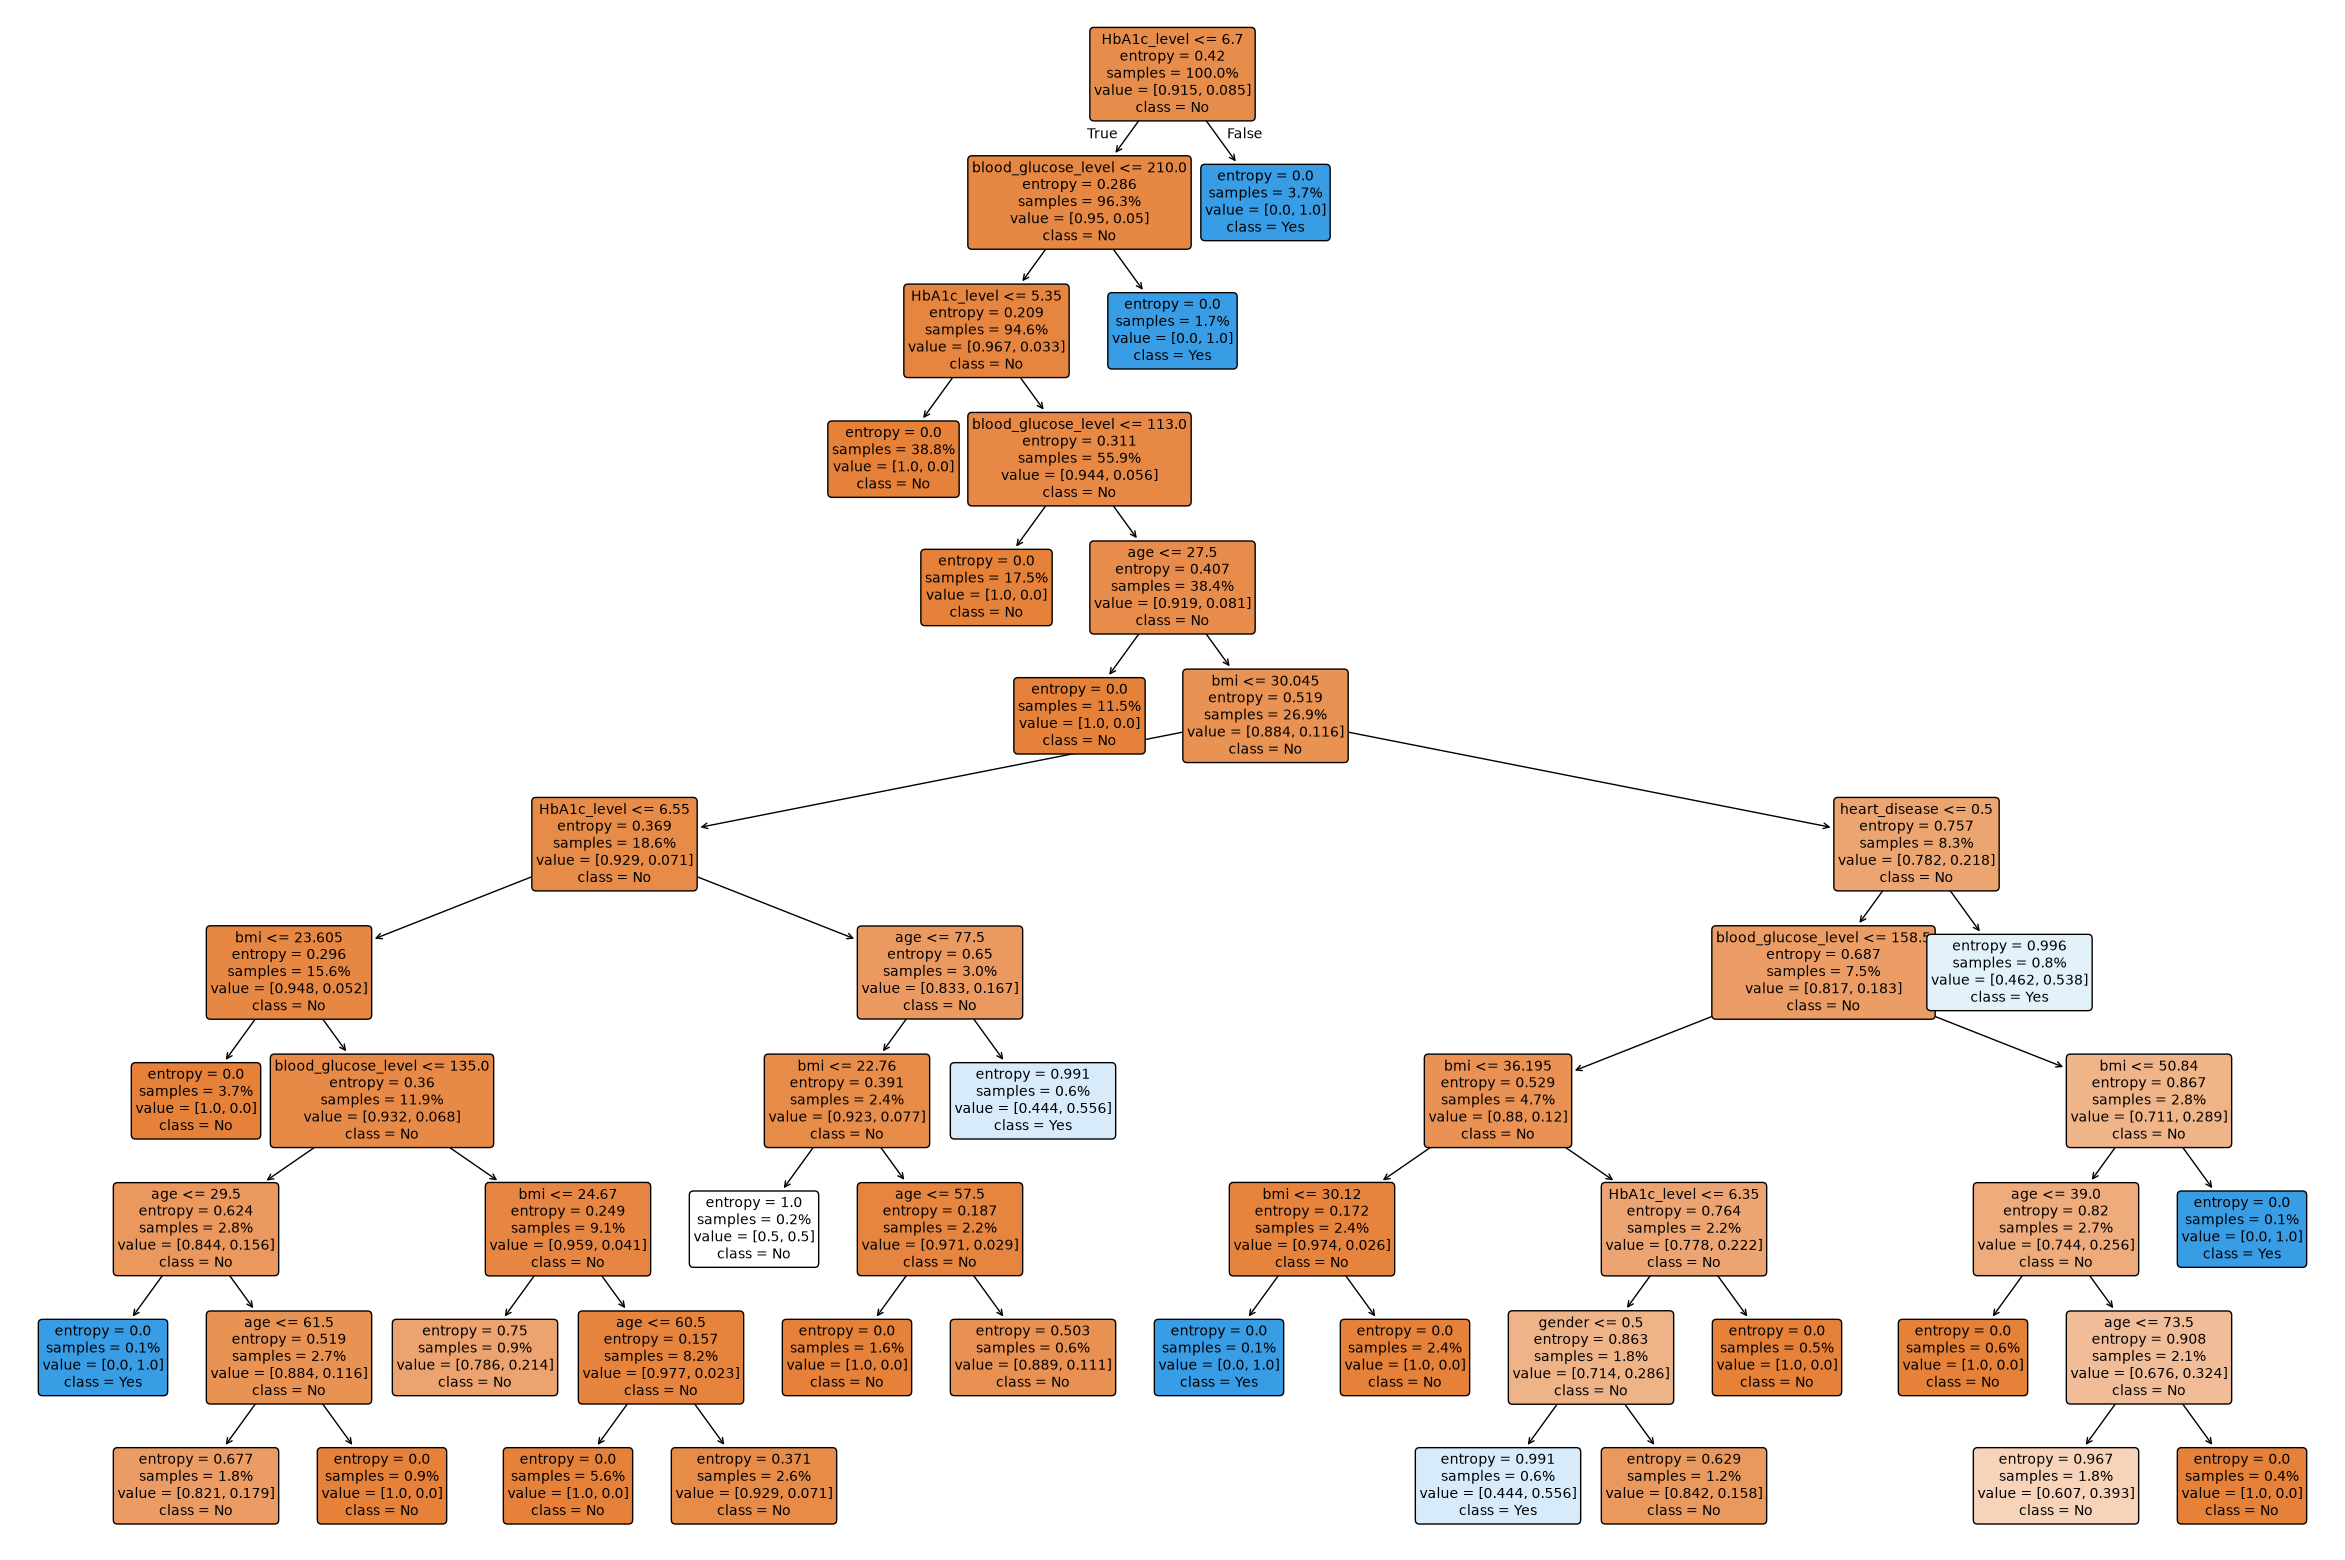

In [2290]:
#KNN model where K = 5:

best_knn = KNeighborsClassifier(n_neighbors=5)
best_knn.fit(train_X_scaled, train_y)
best_pred_knn = best_knn.predict(full_data_scaled)

#DT where max_depth = 11, min_samples_split = 20:

best_DT = DecisionTreeClassifier(criterion='entropy', 
                                    max_depth=11,
                                    min_samples_split=20,
                                    random_state=1101)
best_DT.fit(train_X, train_y)
best_pred_DT = best_DT.predict(full_data)

class_name = ["No", "Yes"]
plt.figure(figsize=[30,20])
plot_tree(best_DT,
          feature_names=train_X.columns,
          class_names=class_name,
          filled=True,
          rounded=True,
          fontsize=10,
          proportion=True,
         )

plt.show()

#LR model / M4:

best_LR = M2
best_pred_LR = (best_LR.predict(full_data) >= threshold).astype(int)

+ TPR and FPR:

In [2282]:
tpr_knn, fpr_knn = tpr_fpr_find(full_diabetes, best_pred_knn)
tpr_DT, fpr_DT = tpr_fpr_find(full_diabetes, best_pred_DT)
tpr_LR, fpr_LR = tpr_fpr_find(full_diabetes, best_pred_LR)

+ Precision:

In [2283]:
precision_knn = round(precision_score(full_diabetes, best_pred_knn),3)
precision_DT = round(precision_score(full_diabetes, best_pred_DT),3)
precision_LR = round(precision_score(full_diabetes, best_pred_LR),3)

+ ROC curve and AUC:

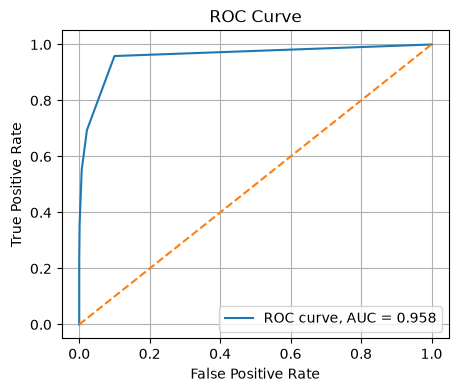

In [2284]:
#KNN:

prob_knn = best_knn.predict_proba(full_data_scaled)[:, 1]
fpr_knn_roc, tpr_knn_roc, thresholds_knn = roc_curve(full_diabetes, prob_knn)
auc_knn = roc_auc_score(full_diabetes, prob_knn)

plt.figure(figsize=(5, 4))
plt.plot(fpr_knn_roc, tpr_knn_roc, label=f"ROC curve, AUC = {auc_knn:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(
    loc="lower right"
)
plt.grid(True)
plt.show()

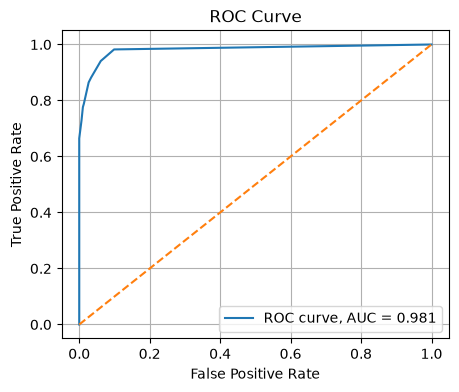

In [2285]:
#DT:
prob_DT = best_DT.predict_proba(full_data)[:, 1]
fpr_DT_roc, tpr_DT_roc, thresholds_DT = roc_curve(full_diabetes, prob_DT)
auc_DT = roc_auc_score(full_diabetes, prob_DT)

plt.figure(figsize=(5, 4))
plt.plot(fpr_DT_roc, tpr_DT_roc, label=f"ROC curve, AUC = {auc_DT:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(
    loc="lower right"
)
plt.grid(True)
plt.show()

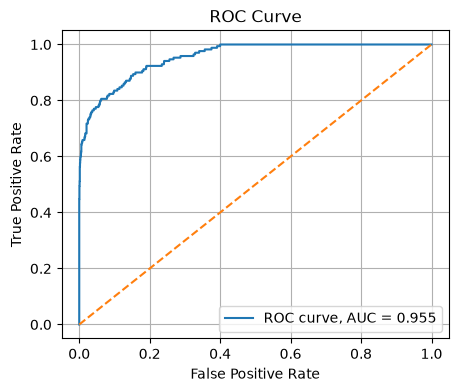

In [2286]:
#LR:
prob_LR = best_LR.predict(full_data)
fpr_LR_roc, tpr_LR_roc, thresholds_LR = roc_curve(full_diabetes, prob_LR)
auc_LR = roc_auc_score(full_diabetes, prob_LR)

plt.figure(figsize=(5, 4))
plt.plot(fpr_LR_roc, tpr_LR_roc, label=f"ROC curve, AUC = {auc_LR:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

In [2287]:
#DataFrame of the three metrics:

df_models = pd.DataFrame({
    "model": ["knn", "decision tree", "logistic regression"],
    "tpr": [tpr_knn, tpr_DT, tpr_LR],
    "fpr": [fpr_knn, fpr_DT, fpr_LR],
    "precision": [precision_knn, precision_DT, precision_LR],
    "auc": [auc_knn, auc_DT, auc_LR]
})

print(df_models)

                 model    tpr    fpr  precision       auc
0                  knn  0.553  0.007      0.879  0.958314
1        decision tree  0.776  0.010      0.874  0.981400
2  logistic regression  0.635  0.006      0.908  0.955196


Evidently, Decision Tree returns the highest TPR and AUC among the three classifiers when making predictions on the full data set. However, to exercise caution as this result may be an optimistic estimation of the model's goodness-of-fit, I will test the three models by using them to predict the diabetes status in the test_set.

The goal is to see if there is a large gap between the models' performance on the three sets. If the answer is yes, there may be an overestimation of how well the models perform in reality.

In [2288]:
#Testing the models on the test_set:

#Using .predict() on the test_set:

pred_knn_test = best_knn.predict(test_X_scaled)
pred_dt_test = best_DT.predict(test_X)
pred_lr_test = (best_LR.predict(test_X) >= threshold).astype(int)

#tpr & fpr:

tpr_knn_test, fpr_knn_test = tpr_fpr_find(test_y, pred_knn_test)
tpr_dt_test, fpr_dt_test = tpr_fpr_find(test_y, pred_dt_test)
tpr_lr_test, fpr_lr_test = tpr_fpr_find(test_y, pred_lr_test)

#precision:

precision_knn_test = round(precision_score(test_y, pred_knn_test),3)
precision_dt_test = round(precision_score(test_y, pred_dt_test),3)
precision_lr_test = round(precision_score(test_y, pred_lr_test),3)

#auc:

prob_knn_test = best_knn.predict_proba(test_X_scaled)[:, 1]
auc_knn_test = roc_auc_score(test_y, prob_knn_test)

prob_dt_test = best_DT.predict_proba(test_X)[:, 1]
auc_dt_test = roc_auc_score(test_y, prob_dt_test)

prob_lr_test = best_LR.predict(test_X)
auc_lr_test = roc_auc_score(test_y, prob_lr_test)

#DataFrame of the three metrics:

df_test_model = pd.DataFrame({
    "model": ["knn", "decision tree", "logistic regression"],
    "tpr": [tpr_knn_test, tpr_dt_test, tpr_lr_test],
    "fpr": [fpr_knn_test, fpr_dt_test, fpr_lr_test],
    "precision": [precision_knn_test, precision_dt_test, precision_lr_test],
    "auc": [auc_knn_test, auc_dt_test, auc_lr_test]
})

print(df_test_model.sort_values(by="tpr", ascending=False))

                 model    tpr    fpr  precision       auc
1        decision tree  0.706  0.014      0.828  0.933502
2  logistic regression  0.559  0.005      0.905  0.939730
0                  knn  0.412  0.008      0.824  0.857441


In [2289]:
#The gap between the metrics achieved during the first test (with the full 2000 subset) and second test (only in the test_set:

df_gap_test = pd.DataFrame({
    "model": ["knn", "decision tree", "logistic regression"],
    "tpr": [tpr_knn - tpr_knn_test, tpr_DT - tpr_dt_test, tpr_LR - tpr_lr_test],
    "fpr": [fpr_knn - fpr_knn_test, fpr_DT - fpr_dt_test, fpr_LR - fpr_lr_test],
    "precision": [precision_knn - precision_knn_test, precision_DT - precision_dt_test, precision_LR - precision_lr_test],
    "auc": [auc_knn - auc_knn_test, auc_DT - auc_dt_test, auc_LR - auc_lr_test]
})

print(df_gap_test.sort_values(by="tpr", ascending=False))

                 model    tpr    fpr  precision       auc
0                  knn  0.141 -0.001      0.055  0.100873
2  logistic regression  0.076  0.001      0.003  0.015466
1        decision tree  0.070 -0.004      0.046  0.047898
